# Supplementary figure: contribution of individual samples to each cell type

For every cell type of the lung single-cell data, the fraction of its cells that comes from each sample is computed.
The heatmap shows the median of this fraction (in %) per sequencing batch. Cell types with fewer than 750 cells are excluded.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from figure_style import SMALL_FONT_SIZE, figure_size, save_panel, set_style

set_style()
DATA = Path("../data")

In [2]:
cell_counts_per_sample = pd.read_csv(DATA / "22_lung_cell_counts_per_sample.csv", index_col=0)

cell_counts = cell_counts_per_sample.sum(axis=1)
small_cell_types = cell_counts[cell_counts < 750].index

# Fraction of cells of each cell type coming from each sample
cells_per_sample = cell_counts_per_sample.drop(index=small_cell_types)
cells_per_sample = cells_per_sample.div(cells_per_sample.sum(axis=1), axis=0)

cells_per_sample_long = cells_per_sample.melt(ignore_index=False, var_name="sample_id").reset_index()
cells_per_sample_long["Batch"] = cells_per_sample_long["sample_id"].str.split("_").str[1]
cells_per_sample_long.shape

(1560, 4)

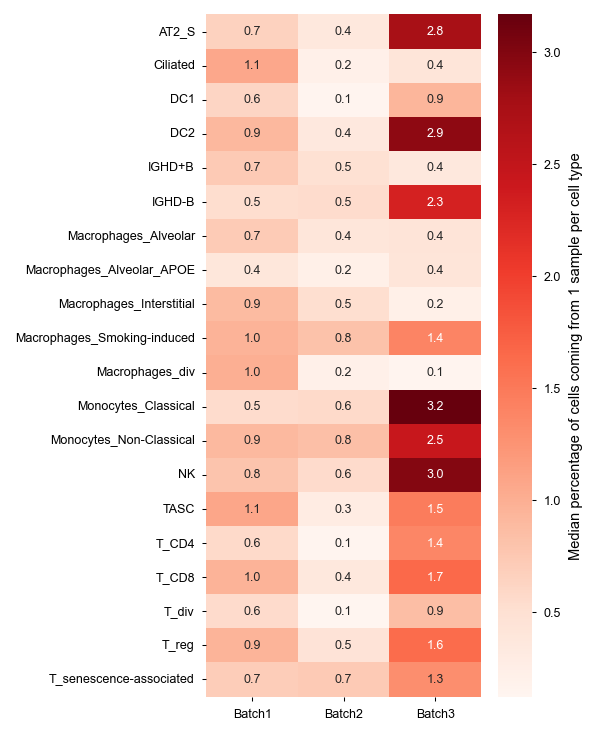

In [3]:
plt.figure(figsize=figure_size(75, 150))
sns.heatmap(
    cells_per_sample_long.groupby(["cell_type", "Batch"])["value"].median().reset_index().pivot(index="cell_type", columns="Batch", values="value") * 100,
    cmap="Reds",
    annot=True,
    fmt=".1f",
    annot_kws={"size": SMALL_FONT_SIZE},
    cbar_kws={"label": "Median percentage of cells coming from 1 sample per cell type"},
)
plt.ylabel("")
plt.xlabel("")
save_panel("Supp_Fig_lung_cells_per_sample_batch")
plt.show()